In [2]:
import torch
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt

transform = transforms.Compose([transforms.ToTensor()])
trainset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
testset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_images = trainset.data.numpy().reshape(-1, 784).astype(np.float32) / 255.0
train_labels = trainset.targets.numpy()
test_images = testset.data.numpy().reshape(-1, 784).astype(np.float32) / 255.0
test_labels = testset.targets.numpy()

print(f"Train: {train_images.shape}, Test: {test_images.shape}")

100%|██████████| 9.91M/9.91M [00:00<00:00, 35.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.14MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 8.81MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.19MB/s]


Train: (60000, 784), Test: (10000, 784)


In [3]:
# Reuse NOC classes from A4 (re-paste if needed in a fresh session)
class NOCAgent:
    def __init__(self, prototype, label):
        self.prototype = prototype.copy()
        self.label = label
        self.correct_count = 1
        self.total_count = 1

    @property
    def fitness(self):
        return self.correct_count / self.total_count

def evaluate_noc(agents, images, labels):
    if len(agents) == 0:
        return 0.0
    predictions = []
    for x in images:
        distances = [np.linalg.norm(x - a.prototype) for a in agents]
        nearest_idx = np.argmin(distances)
        predictions.append(agents[nearest_idx].label)
    return np.mean(np.array(predictions) == labels)

# Build phased data stream: Phase 1 = digits 0-4 only, Phase 2 = digits 5-9 introduced
phase1_mask = train_labels < 5
phase2_mask = train_labels >= 5

phase1_images = train_images[phase1_mask]
phase1_labels = train_labels[phase1_mask]
phase2_images = train_images[phase2_mask]
phase2_labels = train_labels[phase2_mask]

print(f"Phase 1 (digits 0-4): {len(phase1_images)} samples")
print(f"Phase 2 (digits 5-9): {len(phase2_images)} samples")

# Held-out test sets, split by digit group, for tracking adaptation/forgetting
test_old_mask = test_labels < 5
test_new_mask = test_labels >= 5
test_old_images, test_old_labels = test_images[test_old_mask], test_labels[test_old_mask]
test_new_images, test_new_labels = test_images[test_new_mask], test_labels[test_new_mask]

print(f"Test set (old digits 0-4): {len(test_old_images)}")
print(f"Test set (new digits 5-9): {len(test_new_images)}")

Phase 1 (digits 0-4): 30596 samples
Phase 2 (digits 5-9): 29404 samples
Test set (old digits 0-4): 5139
Test set (new digits 5-9): 4861


In [4]:
def train_noc_incremental(phase1_images, phase1_labels, phase2_images, phase2_labels,
                            test_old_images, test_old_labels, test_new_images, test_new_labels,
                            novelty_threshold=8.0, learning_rate=0.05, max_agents=500, prune_every=2000,
                            checkpoint_every=5000):
    agents = []
    history = {'step': [], 'old_acc': [], 'new_acc': [], 'num_agents': []}

    def process_stream(images, labels, start_step):
        step = start_step
        for x, y in zip(images, labels):
            if len(agents) == 0:
                agents.append(NOCAgent(x, y))
            else:
                distances = [np.linalg.norm(x - a.prototype) for a in agents]
                nearest_idx = np.argmin(distances)
                nearest_dist = distances[nearest_idx]

                if nearest_dist > novelty_threshold:
                    if len(agents) < max_agents:
                        agents.append(NOCAgent(x, y))
                else:
                    agent = agents[nearest_idx]
                    agent.total_count += 1
                    if agent.label == y:
                        agent.correct_count += 1
                        agent.prototype += learning_rate * (x - agent.prototype)

            if (step + 1) % prune_every == 0 and len(agents) > 20:
                agents[:] = [a for a in agents if a.fitness > 0.3 or a.total_count < 10]

            if (step + 1) % checkpoint_every == 0:
                old_acc = evaluate_noc(agents, test_old_images, test_old_labels)
                new_acc = evaluate_noc(agents, test_new_images, test_new_labels)
                history['step'].append(step + 1)
                history['old_acc'].append(old_acc)
                history['new_acc'].append(new_acc)
                history['num_agents'].append(len(agents))
                print(f"Step {step+1}: Old-digit acc={old_acc*100:.1f}%, New-digit acc={new_acc*100:.1f}%, Agents={len(agents)}")

            step += 1
        return step

    print("=== Phase 1: Training on digits 0-4 only ===")
    step = process_stream(phase1_images, phase1_labels, 0)

    print("\n=== Phase 2: Introducing digits 5-9 ===")
    step = process_stream(phase2_images, phase2_labels, step)

    return agents, history

agents_incremental, history = train_noc_incremental(
    phase1_images, phase1_labels, phase2_images, phase2_labels,
    test_old_images, test_old_labels, test_new_images, test_new_labels,
    checkpoint_every=5000
)

=== Phase 1: Training on digits 0-4 only ===
Step 5000: Old-digit acc=96.6%, New-digit acc=0.0%, Agents=119
Step 10000: Old-digit acc=97.0%, New-digit acc=0.0%, Agents=145
Step 15000: Old-digit acc=97.2%, New-digit acc=0.0%, Agents=154
Step 20000: Old-digit acc=97.5%, New-digit acc=0.0%, Agents=167
Step 25000: Old-digit acc=97.7%, New-digit acc=0.0%, Agents=181
Step 30000: Old-digit acc=97.6%, New-digit acc=0.0%, Agents=190

=== Phase 2: Introducing digits 5-9 ===
Step 35000: Old-digit acc=96.6%, New-digit acc=58.6%, Agents=260
Step 40000: Old-digit acc=96.0%, New-digit acc=64.9%, Agents=291
Step 45000: Old-digit acc=95.6%, New-digit acc=73.3%, Agents=310
Step 50000: Old-digit acc=95.1%, New-digit acc=79.8%, Agents=319
Step 55000: Old-digit acc=94.7%, New-digit acc=81.5%, Agents=336
Step 60000: Old-digit acc=94.8%, New-digit acc=81.4%, Agents=349


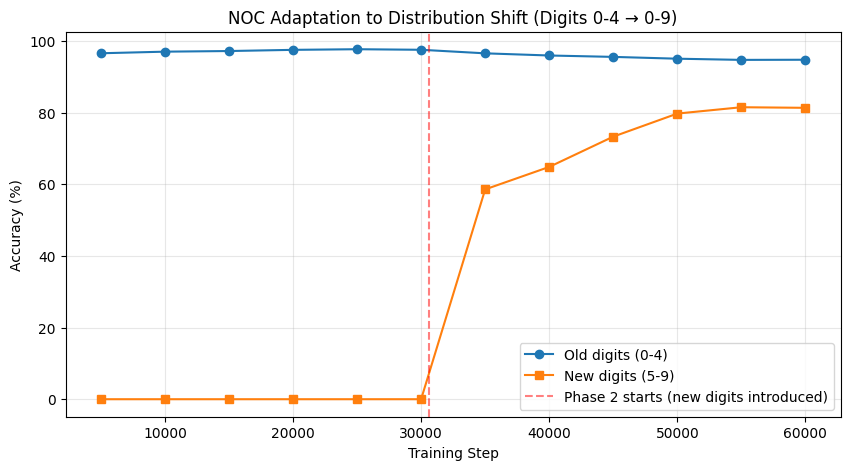


Peak old-digit accuracy (end of Phase 1): 97.7%
Final old-digit accuracy (end of Phase 2): 94.8%
Forgetting: 2.9 percentage points
Final new-digit accuracy: 81.4%
Final total agents: 349


In [5]:
plt.figure(figsize=(10,5))
plt.plot(history['step'], [a*100 for a in history['old_acc']], marker='o', label='Old digits (0-4)')
plt.plot(history['step'], [a*100 for a in history['new_acc']], marker='s', label='New digits (5-9)')
plt.axvline(x=30596, color='red', linestyle='--', alpha=0.5, label='Phase 2 starts (new digits introduced)')
plt.xlabel('Training Step')
plt.ylabel('Accuracy (%)')
plt.title('NOC Adaptation to Distribution Shift (Digits 0-4 → 0-9)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

final_old_acc = history['old_acc'][-1]
final_new_acc = history['new_acc'][-1]
peak_old_acc = max(history['old_acc'])
print(f"\nPeak old-digit accuracy (end of Phase 1): {peak_old_acc*100:.1f}%")
print(f"Final old-digit accuracy (end of Phase 2): {final_old_acc*100:.1f}%")
print(f"Forgetting: {(peak_old_acc-final_old_acc)*100:.1f} percentage points")
print(f"Final new-digit accuracy: {final_new_acc*100:.1f}%")
print(f"Final total agents: {history['num_agents'][-1]}")

In [5]:
final_old_acc = history['old_acc'][-1]
final_new_acc = history['new_acc'][-1]
peak_old_acc = max(history['old_acc'])
print(f"Peak old-digit accuracy (end of Phase 1): {peak_old_acc*100:.1f}%")
print(f"Final old-digit accuracy (end of Phase 2): {final_old_acc*100:.1f}%")
print(f"Forgetting: {(peak_old_acc-final_old_acc)*100:.1f} percentage points")
print(f"Final new-digit accuracy: {final_new_acc*100:.1f}%")
print(f"Final total agents: {history['num_agents'][-1]}")

# Overall accuracy on full 10-digit test set, for direct comparison to A4's 90.74%
overall_acc_incremental = evaluate_noc(agents_incremental, test_images, test_labels)
print(f"\nOverall accuracy (all 10 digits, incremental model): {overall_acc_incremental*100:.2f}%")
print(f"A4's from-scratch baseline (all 10 digits, trained together): 90.74%")

Peak old-digit accuracy (end of Phase 1): 97.7%
Final old-digit accuracy (end of Phase 2): 94.8%
Forgetting: 2.9 percentage points
Final new-digit accuracy: 81.4%
Final total agents: 349

Overall accuracy (all 10 digits, incremental model): 88.26%
A4's from-scratch baseline (all 10 digits, trained together): 90.74%


In [6]:
overall_acc_incremental = evaluate_noc(agents_incremental, test_images, test_labels)
print(f"Overall accuracy (all 10 digits, incremental model): {overall_acc_incremental*100:.2f}%")
print(f"A4's from-scratch baseline (all 10 digits, trained together): 90.74%")

Overall accuracy (all 10 digits, incremental model): 88.26%
A4's from-scratch baseline (all 10 digits, trained together): 90.74%
